In [1]:
import importlib
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

CODE_DIR = Path.cwd().parent if Path.cwd().name == "train-notebooks" else Path.cwd()
if not ((CODE_DIR / "kev").is_dir() and (CODE_DIR / "data").is_dir() and (CODE_DIR / "training").is_dir()):
    raise RuntimeError(f"Expected code/ root containing kev/, data/, and training/; got {CODE_DIR}")
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev")):
    if _p not in sys.path:
        sys.path.insert(0, _p)

import data.persona as _persona_mod
import data.base as _base_mod
import data.marginals as _marginals_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.twin2k_megastudy as _twin2k_megastudy_mod
import data.grummon2023 as _grummon2023_mod
import data.grummon2025 as _grummon2025_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training.iid_trainer as _iid_trainer_mod
import training.marginal_trainer as _marginal_trainer_mod
import training.chunked_trainer as _chunked_trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _marginals_mod,
    _issp_mod,
    _twin2k_mod,
    _twin2k_megastudy_mod,
    _grummon2023_mod,
    _grummon2025_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _iid_trainer_mod,
    _marginal_trainer_mod,
    _chunked_trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon2023 import load_grummon2023_df
from data.grummon2025 import ARM_NAMES, PRIMARY_CHOICE_STEMS, load_grummon2025
from data.issp import load_issp_df
from data.marginals import DEFAULT_K_SCHEDULE, build_marginal_lookup
from data.twin2k import load_twin2k_df
from data.twin2k_megastudy import load_twin2k_megastudy_df
from training import ChunkedMarginalTrainer, free_gpu

print(f"Working directory: {Path.cwd()}")

Working directory: /home/dw/github/decision-models-finetuning/code


## 1. Load datasets and build out-of-study choice validation split

In [61]:
INCLUDE_COUNTRY = False
VALID_SEED = 0
VALID_ISSP_YEAR = "2022"
TWIN_VALID_CASEID_SHARE = 0.50
MAX_ISSP_VALID_RESP_PER_QID = 50
MAX_SIM_THRESHOLD = 0.75

issp_df = load_issp_df()
twin_df = load_twin2k_df()
mega_df = load_twin2k_megastudy_df()
grummon2023_df = load_grummon2023_df()
all_df = pd.concat([issp_df, twin_df, mega_df, grummon2023_df], ignore_index=True)

for _name, _df in [("ISSP", issp_df), ("Twin-2K", twin_df), ("Twin mega", mega_df), ("Grummon 2023", grummon2023_df)]:
    for _col in ("CASEID", "qid", "type", "question", "one_hot"):
        if _col not in _df.columns:
            raise KeyError(f"{_name} missing required column {_col!r}")

print(
    f"ISSP         : {len(issp_df):>10,} rows | {issp_df['qid'].nunique():>4} qids | choice={(issp_df['type'] == 'choice').sum():>8,}\n"
    f"Twin-2K      : {len(twin_df):>10,} rows | {twin_df['qid'].nunique():>4} qids | choice={(twin_df['type'] == 'choice').sum():>8,}\n"
    f"Twin mega    : {len(mega_df):>10,} rows | {mega_df['qid'].nunique():>4} qids | choice={(mega_df['type'] == 'choice').sum():>8,}\n"
    f"Grummon 2023 : {len(grummon2023_df):>10,} rows | {grummon2023_df['qid'].nunique():>4} qids | choice={(grummon2023_df['type'] == 'choice').sum():>8,}\n"
    f"Total        : {len(all_df):>10,} rows | {all_df['qid'].nunique():>4} qids | choice={(all_df['type'] == 'choice').sum():>8,}"
)

ISSP         :    767,484 rows |  616 qids | choice= 150,188
Twin-2K      :  1,127,649 rows |  974 qids | choice= 572,130
Twin mega    :    287,033 rows | 2835 qids | choice=  56,841
Grummon 2023 :    254,145 rows |  160 qids | choice=  47,654
Total        :  2,436,311 rows | 4585 qids | choice= 826,813


### Hold out ISSP 2022 wave (choice questions for validation)

In [62]:
issp_year = issp_df["qid"].str.split(":").str[0]
if (issp_year == VALID_ISSP_YEAR).sum() == 0:
    raise ValueError(f"No ISSP rows found for year {VALID_ISSP_YEAR!r}")

DROP_ISSP_QIDS = sorted(issp_df.loc[issp_year == VALID_ISSP_YEAR, "qid"].unique())
VALID_ISSP_QIDS = sorted(
    issp_df.loc[(issp_year == VALID_ISSP_YEAR) & (issp_df["type"] == "choice"), "qid"].unique()
)
if not VALID_ISSP_QIDS:
    raise ValueError(f"No choice questions found in ISSP {VALID_ISSP_YEAR}")

print(
    f"ISSP {VALID_ISSP_YEAR}: dropping {len(DROP_ISSP_QIDS)} total qids from train; "
    f"keeping {len(VALID_ISSP_QIDS)} choice qids for valid (<= {MAX_ISSP_VALID_RESP_PER_QID} resp/qid)"
)

ISSP 2022: dropping 55 total qids from train; keeping 23 choice qids for valid (<= 50 resp/qid)


### Hold out shared Twin-2K and Twin mega respondents plus Twin-2K choice RCTs

In [63]:
import random

rng = random.Random(VALID_SEED)

all_twin_caseids = sorted(set(twin_df["CASEID"].unique()) | set(mega_df["CASEID"].unique()))
n_valid_twin_caseids = round(TWIN_VALID_CASEID_SHARE * len(all_twin_caseids))
VALID_TWIN_CASEIDS = set(rng.sample(all_twin_caseids, n_valid_twin_caseids))

# Between-subject framing choice RCTs in Twin-2K (unseen tasks + unseen respondents)
VALID_TWIN_QIDS = []
missing_twin = set(VALID_TWIN_QIDS) - set(twin_df.loc[twin_df["type"] == "choice", "qid"].unique())
if missing_twin:
    raise KeyError(f"Expected choice qids missing in twin_df: {sorted(missing_twin)}")

print(
    f"Shared twin_* CASEID pool : {len(all_twin_caseids):,} total -> {len(VALID_TWIN_CASEIDS):,} held out ({TWIN_VALID_CASEID_SHARE:.0%})\n"
    f"Twin-2K valid choice qids : {len(VALID_TWIN_QIDS)} ({VALID_TWIN_QIDS})"
)

Shared twin_* CASEID pool : 2,058 total -> 1,029 held out (50%)
Twin-2K valid choice qids : 0 ([])


In [64]:
twin_df.columns

Index(['CASEID', 'c_alphan', 'US_REG', 'SEX', 'AGE', 'EDULEVEL', 'RACE',
       'MARITAL', 'RELIGGRP', 'ATTEND', 'US_PRTY', 'US_INC', 'PARTY_LR',
       'HHSIZE', 'MAINSTAT', 'v', 'label', 'question', 'type', 'reversed',
       'option_codes', 'option_texts', 'answer_code', 'answer_text', 'year',
       'qid', 'one_hot'],
      dtype='str')

In [65]:
for q in twin_df[twin_df.qid.apply(lambda x: x in VALID_TWIN_QIDS)]['question'].unique():
    print(q)
    subset = twin_df[twin_df['question']==q]
    print(subset['option_texts'].iloc[0])
    print('+'*50)

### Hold out Twin mega choice sub-studies

In [66]:
HOLD_MEGA_STUDIES = ("context-effects", "digital-certification")
mega_study_col = mega_df["qid"].str.split(":", n=1).str[1].str.rsplit("-QID", n=1).str[0]
missing_studies = set(HOLD_MEGA_STUDIES) - set(mega_study_col.unique())
if missing_studies:
    raise KeyError(f"Expected mega sub-studies not found: {sorted(missing_studies)}")

# Drop every question in held-out sub-studies from train_df (including manipulation checks / background screens)
DROP_MEGA_QIDS = sorted(mega_df.loc[mega_study_col.isin(HOLD_MEGA_STUDIES), "qid"].unique())

# Keep the 10 context-effects choice tasks + digital-certification QID199 (6-sweater product choice; exclude QID194 ownership screen)
VALID_MEGA_QIDS = sorted(
    mega_df.loc[
        (mega_study_col == "context-effects") & (mega_df["type"] == "choice"),
        "qid",
    ].unique()
) + ["twin2k-mega:digital-certification-QID199"]

missing_mega_valid = set(VALID_MEGA_QIDS) - set(mega_df.loc[mega_df["type"] == "choice", "qid"].unique())
if missing_mega_valid:
    raise KeyError(f"Expected choice qids missing in mega_df: {sorted(missing_mega_valid)}")

mega_summary = (
    mega_df[mega_study_col.isin(HOLD_MEGA_STUDIES)]
    .assign(
        study=mega_study_col[mega_study_col.isin(HOLD_MEGA_STUDIES)],
        in_valid_qids=lambda d: d["qid"].isin(VALID_MEGA_QIDS),
        in_valid_caseids=lambda d: d["CASEID"].isin(VALID_TWIN_CASEIDS),
    )
    .groupby(["study", "qid", "type"], as_index=False)
    .agg(
        total_rows=("CASEID", "size"),
        valid_rows=("in_valid_caseids", lambda s: int(s.sum())),
        selected_for_valid=("in_valid_qids", "first"),
    )
)
display(mega_summary)

,study,qid,type,total_rows,valid_rows,selected_for_valid
0,context-effects,twin2k-mega:context-effects-QID544,choice,501,256,True
1,context-effects,twin2k-mega:context-effects-QID557,choice,166,84,True
2,context-effects,twin2k-mega:context-effects-QID559,choice,168,89,True
3,context-effects,twin2k-mega:context-effects-QID561,choice,167,83,True
4,context-effects,twin2k-mega:context-effects-QID565,choice,167,89,True
5,context-effects,twin2k-mega:context-effects-QID567,choice,166,78,True
6,context-effects,twin2k-mega:context-effects-QID571,choice,167,94,True
7,context-effects,twin2k-mega:context-effects-QID573,choice,168,78,True
8,context-effects,twin2k-mega:context-effects-QID577,choice,167,73,True
9,context-effects,twin2k-mega:context-effects-QID579,choice,167,100,True


### Grummon 2023 (100% retained in train)

In [67]:
# Keep 100% of Grummon 2023 in train_df (bev_choice and snack_choice share a 0.918-similarity prompt template)
print(
    f"Grummon 2023 retained in train: {len(grummon2023_df):,} rows | "
    f"{grummon2023_df['qid'].nunique()} qids | choice={(grummon2023_df['type'] == 'choice').sum():,}"
)

Grummon 2023 retained in train: 254,145 rows | 160 qids | choice=47,654


### Assemble train_df and valid_df and audit prompt similarity (rapidfuzz)

In [68]:
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS + VALID_MEGA_QIDS
if len(VALID_QIDS) != len(set(VALID_QIDS)):
    raise ValueError("Duplicate qids in VALID_QIDS")

train_issp_df = issp_df[~issp_df["qid"].isin(DROP_ISSP_QIDS)]
train_twin_df = twin_df[
    (~twin_df["CASEID"].isin(VALID_TWIN_CASEIDS)) & (~twin_df["qid"].isin(VALID_TWIN_QIDS))
]
train_mega_df = mega_df[
    (~mega_df["CASEID"].isin(VALID_TWIN_CASEIDS)) & (~mega_df["qid"].isin(DROP_MEGA_QIDS))
]
train_grummon2023_df = grummon2023_df

train_df = pd.concat(
    [train_issp_df, train_twin_df, train_mega_df, train_grummon2023_df],
    ignore_index=True,
)

valid_issp_full_df = issp_df[issp_df["qid"].isin(VALID_ISSP_QIDS)]
valid_issp_df = pd.concat(
    [
        g.sample(n=min(len(g), MAX_ISSP_VALID_RESP_PER_QID), random_state=VALID_SEED)
        for _, g in valid_issp_full_df.groupby("qid", sort=True)
    ],
    ignore_index=True,
)
valid_twin_df = twin_df[
    twin_df["CASEID"].isin(VALID_TWIN_CASEIDS) & twin_df["qid"].isin(VALID_TWIN_QIDS)
]
valid_mega_df = mega_df[
    mega_df["CASEID"].isin(VALID_TWIN_CASEIDS) & mega_df["qid"].isin(VALID_MEGA_QIDS)
]

valid_df = pd.concat([valid_issp_df, valid_twin_df, valid_mega_df], ignore_index=True)

print(
    f"train_df : {len(train_df):>10,} rows | {train_df['qid'].nunique():>4} qids | "
    f"choice={(train_df['type'] == 'choice').sum():,} / {(all_df['type'] == 'choice').sum():,} "
    f"({(train_df['type'] == 'choice').sum() / (all_df['type'] == 'choice').sum():.1%})\n"
    f"valid_df : {len(valid_df):>10,} rows | {valid_df['qid'].nunique():>4} qids | "
    f"{valid_df['CASEID'].nunique():,} unseen respondents\n"
    f"  ISSP 2022 : {len(valid_issp_df):>6,} rows across {valid_issp_df['qid'].nunique():>2} choice qids\n"
    f"  Twin-2K   : {len(valid_twin_df):>6,} rows across {valid_twin_df['qid'].nunique():>2} choice qids\n"
    f"  Twin mega : {len(valid_mega_df):>6,} rows across {valid_mega_df['qid'].nunique():>2} choice qids"
)

train_df :  1,676,364 rows | 4492 qids | choice=493,159 / 826,813 (59.6%)
valid_df :      2,484 rows |   34 qids | 1,072 unseen respondents
  ISSP 2022 :  1,150 rows across 23 choice qids
  Twin-2K   :      0 rows across  0 choice qids
  Twin mega :  1,334 rows across 11 choice qids


In [69]:
valid_df['battery'] = valid_df['qid'].apply(lambda x: x.split(':')[0].strip())
valid_df.groupby('battery')['qid'].count()

battery
2022           1150
twin2k-mega    1334
Name: qid, dtype: int64

In [70]:
# valid_df[['qid', 'question', 'option_texts']].drop_duplicates('question')

In [71]:
import numpy as np
from rapidfuzz import fuzz, process

q_text_map = all_df.groupby("qid")["question"].first().str.strip().to_dict()
train_unique_qids = sorted(train_df["qid"].unique())
valid_unique_qids = sorted(valid_df["qid"].unique())

sim_matrix = process.cdist(
    [q_text_map[q] for q in valid_unique_qids],
    [q_text_map[q] for q in train_unique_qids],
    scorer=fuzz.ratio,
    dtype=np.float64,
    workers=-1,
) / 100.0
best_idx = sim_matrix.argmax(axis=1)
sim_audit_df = pd.DataFrame({
    "valid_qid": valid_unique_qids,
    "closest_train_qid": [train_unique_qids[j] for j in best_idx],
    "fuzz_ratio": [float(sim_matrix[i, j]) for i, j in enumerate(best_idx)],
    "valid_question": [q_text_map[q][:100] for q in valid_unique_qids],
    "closest_train_question": [q_text_map[train_unique_qids[j]][:100] for j in best_idx],
}).sort_values("fuzz_ratio", ascending=False, ignore_index=True)

max_train_valid_sim = float(sim_audit_df["fuzz_ratio"].max())
if max_train_valid_sim >= MAX_SIM_THRESHOLD:
    leaks = sim_audit_df[sim_audit_df["fuzz_ratio"] >= MAX_SIM_THRESHOLD]
    raise ValueError(
        f"{len(leaks)} valid question(s) have fuzz_ratio >= {MAX_SIM_THRESHOLD}:\n"
        f"{leaks[['valid_qid', 'closest_train_qid', 'fuzz_ratio']].to_string(index=False)}"
    )

print(
    f"Max valid-vs-train fuzz.ratio = {max_train_valid_sim:.3f} "
    f"(< {MAX_SIM_THRESHOLD:.2f} ceiling across all {len(valid_unique_qids)} valid qids)"
)
display(sim_audit_df.head(10))

Max valid-vs-train fuzz.ratio = 0.693 (< 0.75 ceiling across all 34 valid qids)


,valid_qid,closest_train_qid,fuzz_ratio,valid_question,closest_train_question
0,2022:v8,2020:v17,0.693410,People have different opinions about how well ...,There has been a lot of discussion about the w...
1,2022:v30,2017:v16,0.691176,People have different views on childcare for c...,People have different opinions on who should p...
2,2022:v7,2020:v17,0.655367,People have different opinions about how much ...,There has been a lot of discussion about the w...
3,2022:v10,2021:v56,0.562092,"Do you think that women should work full-time,...",Do you think the United States' government sho...
4,2022:v9,2021:v56,0.562092,"Do you think that women should work full-time,...",Do you think the United States' government sho...
5,2022:v39,2024:v23,0.561151,In your household who does the following thing...,How would you rate your ability to do the foll...
6,2022:v44,2024:v24,0.541667,In your household who does the following thing...,How would you rate your ability to do the foll...
7,2022:v50,2020:v17,0.539007,People may have different perceptions about wh...,There has been a lot of discussion about the w...
8,2022:v42,2024:v24,0.537931,In your household who does the following thing...,How would you rate your ability to do the foll...
9,2022:v32,2017:v15,0.533708,Thinking about elderly people who need some he...,People have different opinions on who should p...


In [72]:
valid_df.columns
valid_df.groupby(['qid'])['CASEID'].nunique().value_counts()

CASEID
50     23
89      2
78      2
256     1
84      1
83      1
94      1
73      1
100     1
310     1
Name: count, dtype: int64

### build datasets

In [73]:
train_records = build_persona_dataset(
    train_df,
    attr_sets=None,
    include_country=INCLUDE_COUNTRY,
    desc=f"train_records_v3_validchoice_s{VALID_SEED}",
)
marginal_lookup = build_marginal_lookup(train_df, include_country=INCLUDE_COUNTRY)

valid_grouped = build_eval_set(
    valid_df,
    attr_sets=None,
    include_country=INCLUDE_COUNTRY,
    grouped=True,
    name="valid_choice",
    valid=True,
)
GRUMMON2025_QIDS = [f"grummon2025:{arm}:{v}" for arm in ARM_NAMES for v in PRIMARY_CHOICE_STEMS]
grummon2025_grouped = load_grummon2025(
    attr_sets=None,
    include_country=INCLUDE_COUNTRY,
    grouped=True,
    valid=False,
    qids=GRUMMON2025_QIDS,
)

eval_records = [valid_grouped, grummon2025_grouped]

print(
    f"Train records : {len(train_records):,} ({train_df['qid'].nunique():,} questions | "
    f"{marginal_lookup.num_unique_personas:,} unique personas, {len(marginal_lookup.trait_masks)} trait-value masks)\n"
    f"Eval sets     : valid_choice={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon2025={len(grummon2025_grouped['records']):,} ({len(grummon2025_grouped['packed_views']):,} states)"
)

train_records_v3_validchoice_s0:   0%|          | 0/4492 [00:00<?, ?question/s]

Saved 1,676,364 records to train_records_v3_validchoice_s0_minNone_aca89c95.pkl


valid_choice_records:   0%|          | 0/34 [00:00<?, ?question/s]

Saved 2,484 records to valid_choice_records_minNone_011c52f5.pkl
Train records : 1,676,364 (4,492 questions | 22,008 unique personas, 224 trait-value masks)
Eval sets     : valid_choice=2,484 (1,070 states), grummon2025=33,798 (4,727 states)


In [74]:
train_rec_qids = set(train_df["qid"].unique())
valid_rec_qids = {r["qid"] for r in valid_grouped["records"]}
grummon2025_rec_qids = {r["qid"] for r in grummon2025_grouped["records"]}

train_caseids = set(train_df["CASEID"].unique())
valid_caseids = set(valid_df["CASEID"].unique())
valid_rec_caseids = {r["CASEID"] for r in valid_grouped["records"]}

train_rec_texts = set(train_df["question"].str.strip().unique())
valid_rec_texts = {r["question"].strip() for r in valid_grouped["records"]}
grummon2025_rec_texts = {r["question"].strip() for r in grummon2025_grouped["records"]}

assert valid_rec_qids == set(VALID_QIDS), (
    f"Missing valid qids after CASEID filter: {sorted(set(VALID_QIDS) - valid_rec_qids)}"
)
assert train_caseids.isdisjoint(valid_caseids), (
    f"Train/Valid CASEID overlap: {len(train_caseids & valid_caseids)} respondents"
)
assert train_caseids.isdisjoint(valid_rec_caseids), (
    f"Train/Valid record CASEID overlap: {len(train_caseids & valid_rec_caseids)} respondents"
)
assert (valid_df["type"] == "choice").all(), (
    f"Expected 100% choice in valid_df, got {valid_df['type'].value_counts().to_dict()}"
)
assert all(r["type"] == "choice" for r in valid_grouped["records"]), (
    "Expected 100% choice records in valid_grouped!"
)
assert max_train_valid_sim < MAX_SIM_THRESHOLD, (
    f"Expected max fuzz.ratio < {MAX_SIM_THRESHOLD}, got {max_train_valid_sim:.3f}"
)
assert train_rec_qids.isdisjoint(valid_rec_qids), f"Train/Valid QID overlap: {train_rec_qids & valid_rec_qids}"
assert train_rec_qids.isdisjoint(grummon2025_rec_qids), f"Train/Grummon 2025 QID overlap: {train_rec_qids & grummon2025_rec_qids}"
assert train_rec_texts.isdisjoint(valid_rec_texts), "Exact question text overlap between train and valid!"
assert train_rec_texts.isdisjoint(grummon2025_rec_texts), "Exact question text overlap between train and grummon2025!"
assert valid_rec_texts.isdisjoint(grummon2025_rec_texts), "Exact question text overlap between valid and grummon2025!"

print(
    f"QID counts       : train={len(train_rec_qids):,}, valid_choice={len(valid_rec_qids):,}, grummon2025={len(grummon2025_rec_qids):,}\n"
    f"CASEID counts    : train={len(train_caseids):,}, valid_choice={len(valid_rec_caseids):,}, overlap={len(train_caseids & valid_rec_caseids)}\n"
    f"Valid task types : {pd.Series([r['type'] for r in valid_grouped['records']]).value_counts().to_dict()}\n"
    f"Max fuzz.ratio   : {max_train_valid_sim:.3f} (< {MAX_SIM_THRESHOLD:.2f})\n"
    f"Question overlaps: train∩valid={len(train_rec_texts & valid_rec_texts)}, "
    f"train∩grummon2025={len(train_rec_texts & grummon2025_rec_texts)}, "
    f"valid∩grummon2025={len(valid_rec_texts & grummon2025_rec_texts)}"
)

QID counts       : train=4,492, valid_choice=34, grummon2025=36
CASEID counts    : train=22,204, valid_choice=1,072, overlap=0
Valid task types : {'choice': 2484}
Max fuzz.ratio   : 0.693 (< 0.75)
Question overlaps: train∩valid=0, train∩grummon2025=0, valid∩grummon2025=0


### See what happens in the new chunked trainer data processing stage

In [14]:
import random
from collections import Counter

from data.base import _record_chars
from data.marginals import build_marginal_epoch_groups
from training.chunked_trainer import (
    build_logical_marginal_groups,
    sample_persona_state,
    split_logical_group_into_microchunks,
)

pd.set_option("display.max_colwidth", 300)

SEED = 0
TARGET_N = 90                                   # track a persona with about this many training questions
V1_MAX_Q, V1_MAX_CHARS, V1_PER_STEP = 32, 20_000, 12
V2_QPG, V2_PER_STEP = 80, 12
V2_MICRO_Q, V2_MICRO_CHARS = 32, 20_000


def source(qid):
    head = qid.split(":")[0]
    return "issp" if head.isdigit() else head


def persona_key(r):
    return tuple(sorted(r["personas"].items()))


counts = Counter(persona_key(r) for r in train_records)
track_key = min(counts, key=lambda k: abs(counts[k] - TARGET_N))
tracked_records = [dict(r, track=True) if persona_key(r) == track_key else r for r in train_records]
mine = [r for r in tracked_records if "track" in r]

print(f"Tracked persona ({len(mine)} questions):")
for col, val in track_key:
    print(f"  {col} = {val}")
display(pd.DataFrame({
    "qid": [r["qid"] for r in mine],
    "source": [source(r["qid"]) for r in mine],
    "chars": [_record_chars(r) for r in mine],
}).sort_values("chars").reset_index(drop=True))

Tracked persona (90 questions):
  AGE = 50-64
  ATTEND = Never
  EDULEVEL = College graduate/some postgrad
  MAINSTAT = In paid work
  MARITAL = Married
  PARTY_LR = Liberal
  RELIGGRP = Atheist
  SEX = Male
  URBRURAL = The suburbs or outskirts of a big city
  US_ETHN1 = England and Wales
  US_INC = $100,000 or more
  US_PRTY = Democrat
  US_REG = West
  VOTE_LE = Yes


,qid,source,chars
0,2022:v31,issp,248
1,2016:v6,issp,272
2,2016:v58,issp,285
3,2016:v59,issp,294
4,2016:v54,issp,300
...,...,...,...
85,2022:v53,issp,674
86,2022:v51,issp,715
87,2022:v54,issp,786
88,2016:v40,issp,838


v1

In [15]:
v1_groups = build_marginal_epoch_groups(
    tracked_records, marginal_lookup,
    max_questions=V1_MAX_Q, max_chars=V1_MAX_CHARS,
    rng=random.Random(f"{SEED}:epoch:0"), k_schedule=DEFAULT_K_SCHEDULE,
)

step_rng = random.Random(SEED)                  # trainer.rng: one persona-order shuffle per group, in epoch order
v1_rows = []
for pos, g in enumerate(v1_groups):
    state = sample_persona_state(g[0]["personas"], rng=step_rng)
    if "track" in g[0]:
        chars = [_record_chars(r) for r in g]
        v1_rows.append({
            "epoch_pos": pos,
            "step": pos // V1_PER_STEP + 1,
            "questions": len(g),
            "sources": dict(Counter(source(r["qid"]) for r in g)),
            "chars_min_max": (min(chars), max(chars)),
            "padded_chars": len(g) * max(chars),
            "forward_passes": 1,
            "k": len(g[0]["personas"]),
            "subpersona": g[0]["attribute"],
            "state_shown": state.replace("\n", " | "),
            "qids": [r["qid"] for r in g],
        })

v1_df = pd.DataFrame(v1_rows)
n_v1_groups = len(v1_groups)
del v1_groups
print(f"v1 epoch: {n_v1_groups:,} groups -> {-(-n_v1_groups // V1_PER_STEP):,} steps")
display(v1_df)

v1 epoch: 95,379 groups -> 7,949 steps


,epoch_pos,step,questions,sources,chars_min_max,padded_chars,forward_passes,k,subpersona,state_shown,qids
0,104,9,32,{'issp': 32},"(248, 378)",12096,1,14,SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1,"Age: 50-64 | Political party: Democrat | Voted in the last general election: Yes | Region: West | Religion: Atheist | Ancestry: England and Wales | Marital status: Married | Income: $100,000 or more | Main activity: In paid work | Education: College graduate/some postgrad | Political ideology: L...","[2022:v31, 2016:v6, 2016:v58, 2016:v59, 2016:v54, 2016:v56, 2016:v1, 2016:v22, 2022:v13, 2016:v46, 2022:v46, 2016:v31, 2016:v21, 2016:v47, 2022:v61, 2016:v50, 2022:v11, 2016:v25, 2022:v49, 2016:v24, 2022:v48, 2016:v29, 2016:v26, 2016:v55, 2016:v27, 2022:v39, 2022:v44, 2016:v49, 2022:v42, 2022:v1..."
1,15468,1290,24,{'issp': 24},"(435, 786)",18864,1,14,SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1,Political ideology: Liberal | Attendance of religious services: Never | Education: College graduate/some postgrad | Voted in the last general election: Yes | Age: 50-64 | Ancestry: England and Wales | Main activity: In paid work | Religion: Atheist | Region: West | Marital status: Married | Sex:...,"[2016:v10, 2016:v15, 2016:v5, 2016:v4, 2016:v43, 2016:v33, 2016:v32, 2022:v1, 2022:v38, 2016:v34, 2016:v38, 2016:v39, 2022:v8, 2022:v25, 2022:v24, 2022:v58, 2022:v7, 2022:v50, 2022:v59, 2022:v57, 2016:v42, 2022:v53, 2022:v51, 2022:v54]"
2,24534,2045,2,{'issp': 2},"(838, 1073)",2146,1,3,RELIGGRP+US_INC+US_ETHN1,"Ancestry: England and Wales | Religion: Atheist | Income: $100,000 or more","[2016:v40, 2016:v35]"
3,70612,5885,32,{'issp': 32},"(378, 434)",13888,1,3,EDULEVEL+PARTY_LR+URBRURAL,Political ideology: Liberal | Education: College graduate/some postgrad | Place of living: The suburbs or outskirts of a big city,"[2022:v41, 2016:v48, 2016:v60, 2016:v3, 2022:v33, 2016:v7, 2022:v2, 2022:v3, 2022:v16, 2022:v15, 2022:v56, 2016:v14, 2022:v4, 2016:v9, 2016:v16, 2022:v18, 2022:v17, 2022:v6, 2016:v12, 2016:v13, 2016:v18, 2016:v11, 2016:v45, 2022:v60, 2016:v20, 2016:v37, 2016:v8, 2016:v19, 2016:v17, 2016:v51, 201..."


v2

In [16]:
v2_groups = build_logical_marginal_groups(
    tracked_records, marginal_lookup,
    questions_per_group=V2_QPG,
    rng=random.Random(f"{SEED}:epoch:0"), k_schedule=DEFAULT_K_SCHEDULE,
)

step_rng = random.Random(SEED)                  # trainer.rng: one persona-order shuffle per logical group
v2_rows, v2_chunk_rows = [], []
for pos, g in enumerate(v2_groups):
    state = sample_persona_state(g[0]["personas"], rng=step_rng)
    if "track" in g[0]:
        chunks = split_logical_group_into_microchunks(
            g, micro_max_questions=V2_MICRO_Q, micro_max_chars=V2_MICRO_CHARS
        )
        v2_rows.append({
            "epoch_pos": pos,
            "step": pos // V2_PER_STEP + 1,
            "questions": len(g),
            "sources": dict(Counter(source(r["qid"]) for r in g)),
            "forward_passes": len(chunks),
            "k": len(g[0]["personas"]),
            "subpersona": g[0]["attribute"],
            "state_shown": state.replace("\n", " | "),
            "qids_in_group_order": [r["qid"] for r in g],
        })
        for j, c in enumerate(chunks):
            chars = [_record_chars(r) for r in c]
            v2_chunk_rows.append({
                "step": pos // V2_PER_STEP + 1,
                "logical_group_pos": pos,
                "chunk": j + 1,
                "questions": len(c),
                "sources": dict(Counter(source(r["qid"]) for r in c)),
                "chars_min_max": (min(chars), max(chars)),
                "padded_chars": len(c) * max(chars),
                "qids": [r["qid"] for r in c],
            })

v2_df = pd.DataFrame(v2_rows)
v2_chunk_df = pd.DataFrame(v2_chunk_rows)
n_v2_groups = len(v2_groups)
del v2_groups
print(f"v2 epoch: {n_v2_groups:,} logical groups -> {-(-n_v2_groups // V2_PER_STEP):,} steps")
display(v2_df)
display(v2_chunk_df)

v2 epoch: 39,723 logical groups -> 3,311 steps


,epoch_pos,step,questions,sources,forward_passes,k,subpersona,state_shown,qids_in_group_order
0,17976,1499,45,{'issp': 45},2,14,SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1,Region: West | Political party: Democrat | Age: 50-64 | Marital status: Married | Voted in the last general election: Yes | Place of living: The suburbs or outskirts of a big city | Ancestry: England and Wales | Political ideology: Liberal | Religion: Atheist | Main activity: In paid work | Sex:...,"[2016:v60, 2016:v54, 2022:v43, 2022:v60, 2022:v8, 2016:v18, 2016:v45, 2022:v17, 2022:v61, 2016:v40, 2022:v56, 2016:v1, 2022:v59, 2022:v48, 2022:v3, 2016:v17, 2016:v38, 2022:v31, 2022:v57, 2016:v51, 2016:v42, 2022:v11, 2022:v16, 2016:v43, 2016:v35, 2022:v15, 2016:v32, 2016:v10, 2022:v44, 2022:v6,..."
1,22743,1896,45,{'issp': 45},2,14,SEX+AGE+EDULEVEL+RELIGGRP+ATTEND+PARTY_LR+VOTE_LE+URBRURAL+MARITAL+MAINSTAT+US_PRTY+US_INC+US_REG+US_ETHN1,"Income: $100,000 or more | Region: West | Sex: Male | Ancestry: England and Wales | Religion: Atheist | Voted in the last general election: Yes | Age: 50-64 | Attendance of religious services: Never | Place of living: The suburbs or outskirts of a big city | Marital status: Married | Education: ...","[2016:v34, 2016:v49, 2016:v58, 2016:v37, 2016:v12, 2016:v33, 2022:v24, 2016:v11, 2016:v30, 2022:v46, 2016:v48, 2022:v50, 2016:v56, 2016:v4, 2022:v1, 2022:v33, 2022:v49, 2022:v7, 2016:v8, 2016:v59, 2016:v50, 2016:v52, 2022:v38, 2016:v53, 2016:v5, 2022:v51, 2016:v19, 2016:v7, 2016:v29, 2016:v55, 2..."


,step,logical_group_pos,chunk,questions,sources,chars_min_max,padded_chars,qids
0,1499,17976,1,32,{'issp': 32},"(248, 433)",13856,"[2022:v31, 2016:v54, 2016:v1, 2016:v22, 2016:v31, 2022:v61, 2022:v11, 2016:v25, 2022:v48, 2016:v26, 2016:v27, 2022:v44, 2022:v14, 2022:v43, 2016:v60, 2016:v3, 2022:v3, 2022:v16, 2022:v15, 2022:v56, 2016:v14, 2022:v4, 2016:v9, 2016:v16, 2022:v18, 2022:v17, 2022:v6, 2016:v18, 2016:v45, 2022:v60, 2..."
1,1499,17976,2,13,{'issp': 13},"(435, 1073)",13949,"[2016:v10, 2016:v43, 2016:v32, 2016:v38, 2016:v39, 2022:v8, 2022:v59, 2022:v57, 2016:v42, 2022:v53, 2022:v54, 2016:v40, 2016:v35]"
2,1896,22743,1,32,{'issp': 32},"(272, 434)",13888,"[2016:v6, 2016:v58, 2016:v59, 2016:v56, 2022:v13, 2016:v46, 2022:v46, 2016:v21, 2016:v47, 2016:v50, 2022:v49, 2016:v24, 2016:v29, 2016:v55, 2022:v39, 2016:v49, 2022:v42, 2016:v30, 2022:v41, 2016:v48, 2022:v33, 2016:v7, 2022:v2, 2016:v12, 2016:v13, 2016:v11, 2016:v20, 2016:v37, 2016:v8, 2016:v19,..."
3,1896,22743,2,13,{'issp': 13},"(436, 715)",9295,"[2016:v15, 2016:v5, 2016:v4, 2016:v33, 2022:v1, 2022:v38, 2016:v34, 2022:v25, 2022:v24, 2022:v58, 2022:v7, 2022:v50, 2022:v51]"


side by side

In [17]:
display(pd.DataFrame({
    "v1": {
        "groups": len(v1_df),
        "steps it appears in": sorted(v1_df["step"]),
        "subpersona draws": len(v1_df),
        "forward passes": int(v1_df["forward_passes"].sum()),
        "mean sources per group": round(v1_df["sources"].map(len).mean(), 2),
    },
    "v2": {
        "groups": len(v2_df),
        "steps it appears in": sorted(v2_df["step"]),
        "subpersona draws": len(v2_df),
        "forward passes": int(v2_df["forward_passes"].sum()),
        "mean sources per group": round(v2_df["sources"].map(len).mean(), 2),
    },
}))

,v1,v2
groups,4,2
steps it appears in,"[9, 1290, 2045, 5885]","[1499, 1896]"
subpersona draws,4,2
forward passes,4,4
mean sources per group,1.0,1.0


In [18]:
v2_groups = build_logical_marginal_groups(
    train_records, marginal_lookup,
    questions_per_group=V2_QPG,
    rng=random.Random(f"{SEED}:epoch:0"), k_schedule=DEFAULT_K_SCHEDULE,
)
k_counts = Counter(min(len(g[0]["personas"]), 6) for g in v2_groups)   # k > 5 can only come from "full"
del v2_groups

k_df = pd.Series(k_counts).sort_index().rename(index={6: ">5 (full)"}).to_frame("groups")
k_df["share"] = (k_df["groups"] / k_df["groups"].sum()).round(3)
display(k_df)

,groups,share
1,5645,0.142
2,5744,0.145
3,5760,0.145
4,5677,0.143
5,5627,0.142
>5 (full),11270,0.284


## 2. Configure & Instantiate Trainer

In [75]:
resume = False
val_every = [50, 50]   # [valid_choice, grummon2025]
save_every = 50
epochs = 1
lr = 5e-5
k_schedule = DEFAULT_K_SCHEDULE   # (1, 2, 3, 4, 5, "full", "full")

trainer_cfg = dict(
    base_model="jaredpalmer/kev-0.8b",
    save_dir="runs/kev-0.8b-v3-issp+twin2k+mega+grummon2023-validchoice-marginals",
    weights_dtype="bf16",
    use_bf16=True,
    gradient_checkpointing=False,
    questions_per_group=80,
    personas_per_step=12,
    micro_max_questions=32,
    micro_max_chars=20_000,
    micro_batch_size=1,
    eval_bf16=True,
    eval_max_questions=1024,
    eval_max_chars=360_000,
)

trainer = None
free_gpu()

trainer = ChunkedMarginalTrainer(
    train_records=train_records,
    eval_records=eval_records,
    marginal_lookup=marginal_lookup,
    k_schedule=k_schedule,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    warmup_steps=2000,
    val_every=val_every,
    resume=resume,
    save_every=save_every,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
trainer,ChunkedMarginalTrainer
run_name,kev-0.8b-v3-issp+twin2k+mega+grummon2023-valid...
save_dir,runs/kev-0.8b-v3-issp+twin2k+mega+grummon2023-...
init_from,jaredpalmer/kev-0.8b
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
resume,False
seed,0
epochs,1


### Probe VRAM across micro-chunk settings

In [20]:
df_probe = trainer.probe_vram([
    (24, 16_000),
    (32, 20_000),
    (40, 24_000),
    (48, 28_000),
])
display(df_probe)

GPU: NVIDIA GeForce RTX 5090 (31.4 GiB total)
micro=(24,  16000, mb=1) -> OK  | peak_alloc=12.26 GiB (reserved=12.47 GiB) | worst=(24, 97, 146) (3,601 toks) | chunks=140,002 (3.52/grp) | 1ep_steps=3,311
micro=(32,  20000, mb=1) -> OK  | peak_alloc=14.31 GiB (reserved=14.70 GiB) | worst=(26, 105, 164) (4,369 toks) | chunks=111,150 (2.80/grp) | 1ep_steps=3,311
micro=(40,  24000, mb=1) -> OK  | peak_alloc=16.30 GiB (reserved=16.73 GiB) | worst=(30, 95, 167) (5,105 toks) | chunks=96,948 (2.44/grp) | 1ep_steps=3,311
micro=(48,  28000, mb=1) -> OK  | peak_alloc=21.83 GiB (reserved=22.66 GiB) | worst=(25, 97, 287) (7,272 toks) | chunks=93,209 (2.35/grp) | 1ep_steps=3,311


,questions_per_group,personas_per_step,micro_max_questions,micro_max_chars,micro_batch_size,logical_groups,micro_chunks,chunks_per_group,steps_per_epoch,total_steps_1ep,"worst_(Q, Ls, Lb)",worst_padded_toks,peak_alloc_GiB,peak_reserved_GiB,status
0,80,12,24,16000,1,39723,140002,3.52,3311,3311,"(24, 97, 146)",3601,12.26,12.47,OK
1,80,12,32,20000,1,39723,111150,2.80,3311,3311,"(26, 105, 164)",4369,14.31,14.70,OK
2,80,12,40,24000,1,39723,96948,2.44,3311,3311,"(30, 95, 167)",5105,16.30,16.73,OK
3,80,12,48,28000,1,39723,93209,2.35,3311,3311,"(25, 97, 287)",7272,21.83,22.66,OK


### Check epoch groups

In [21]:
sample_epoch = trainer._epoch_groups_for(0)

In [22]:
len(sample_epoch)

39723

In [23]:
sample_group_1 = sample_epoch[0]
sample_group_2 = sample_epoch[1]
len(sample_group_1), [r["qid"] for r in sample_group_1[:12]], sample_group_1[0]

(72,
 ['twin2k:QID60',
  'twin2k:QID277_4',
  'twin2k-mega:preference-redistribution-QID28',
  'twin2k:QID247_12',
  'twin2k:QID277_8',
  'twin2k:QID84_4',
  'twin2k:QID232_13',
  'twin2k:QID251_7',
  'twin2k:QID9_216',
  'twin2k-mega:preference-redistribution-QID16',
  'twin2k:QID9_407',
  'twin2k:QID84_12'],
 {'qid': 'twin2k:QID60',
  'year': 'twin2k',
  'v': 'QID60',
  'type': 'choice',
  'question': 'All the cubes below have a different image on each side. Select the choice that could represent a rotation of the cube labeled X Description of Cube X: Cube X has three visible faces, each with a different image: Top face: a plus-shaped black symbol, with dots at the ends of each arm. Left face: a Y-shaped black symbol with rounded ends. Right face: a vertical bar with dots at both ends (like a dumbbell). Options: Each option (A to H) shows a cube with three visible faces. Only one may be a valid rotation of Cube X. Some options also include: D: A box with the text: "None of the cubes 

In [25]:
[r["qid"] for r in sample_group_2[:12]], sample_group_2[0]

(['2015:v72',
  '2015:v3',
  '2015:v78',
  '2015:v75',
  '2015:v82',
  '2015:v77',
  '2015:v19',
  '2015:v9',
  '2015:v83',
  '2015:v81',
  '2015:v84',
  '2015:v17'],
 {'qid': '2015:v72',
  'year': '2015',
  'v': 'v72',
  'type': 'score',
  'question': 'To what extent do you agree or disagree with the following statement? In order to get a job I would be willing … to travel a long time to get to work.',
  'option_texts': ['Strongly agree',
   'Agree',
   'Neither agree nor disagree',
   'Disagree',
   'Strongly disagree'],
  'option_descriptions': None,
  'personas': {'US_PRTY': 'Republican'},
  'attribute': 'US_PRTY',
  'persona': 'Political party=Republican',
  'n': 48,
  'human_dist': array([0.02083333, 0.39583333, 0.10416667, 0.33333333, 0.14583333]),
  'CASEID': 2015008400000965,
  'arm': nan})

In [24]:
[s['n'] for s in sample_group_1]

[1014,
 1014,
 602,
 1014,
 1014,
 1014,
 1014,
 1014,
 83,
 602,
 94,
 1014,
 1014,
 97,
 1014,
 1014,
 94,
 526,
 1014,
 1014,
 1014,
 99,
 1014,
 1014,
 1005,
 1014,
 1014,
 1014,
 1014,
 1014,
 1014,
 689,
 1014,
 689,
 1014,
 602,
 1014,
 689,
 1014,
 1014,
 1014,
 602,
 1014,
 97,
 1014,
 101,
 1014,
 602,
 689,
 1014,
 1014,
 98,
 1014,
 1014,
 526,
 1014,
 689,
 501,
 1014,
 689,
 100,
 1014,
 1014,
 97,
 602,
 501,
 9,
 1014,
 1014,
 233,
 1014,
 689]

In [26]:
[s['n'] for s in sample_group_2]

[48,
 299,
 48,
 48,
 48,
 48,
 296,
 299,
 114,
 48,
 115,
 298,
 291,
 47,
 48,
 278,
 299,
 48,
 297,
 48,
 48,
 48,
 111,
 111,
 298,
 47,
 113,
 48,
 295,
 115,
 298,
 48,
 48,
 298,
 299,
 298,
 298,
 269,
 298]

In [29]:
len(sample_epoch[0]), len(sample_epoch[1]), len(sample_epoch[2])

(72, 39, 31)

In [34]:
sum([len(s) for s in sample_epoch[:12]])

642

<Axes: >

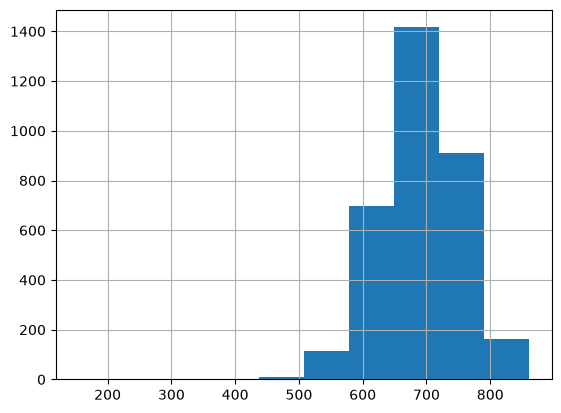

In [36]:
step_questions = [sum(len(g) for g in sample_epoch[s : s + 12]) for s in range(0, len(sample_epoch), 12)]
pd.Series(step_questions, name="questions_per_step").hist()

## 3. Train one epoch

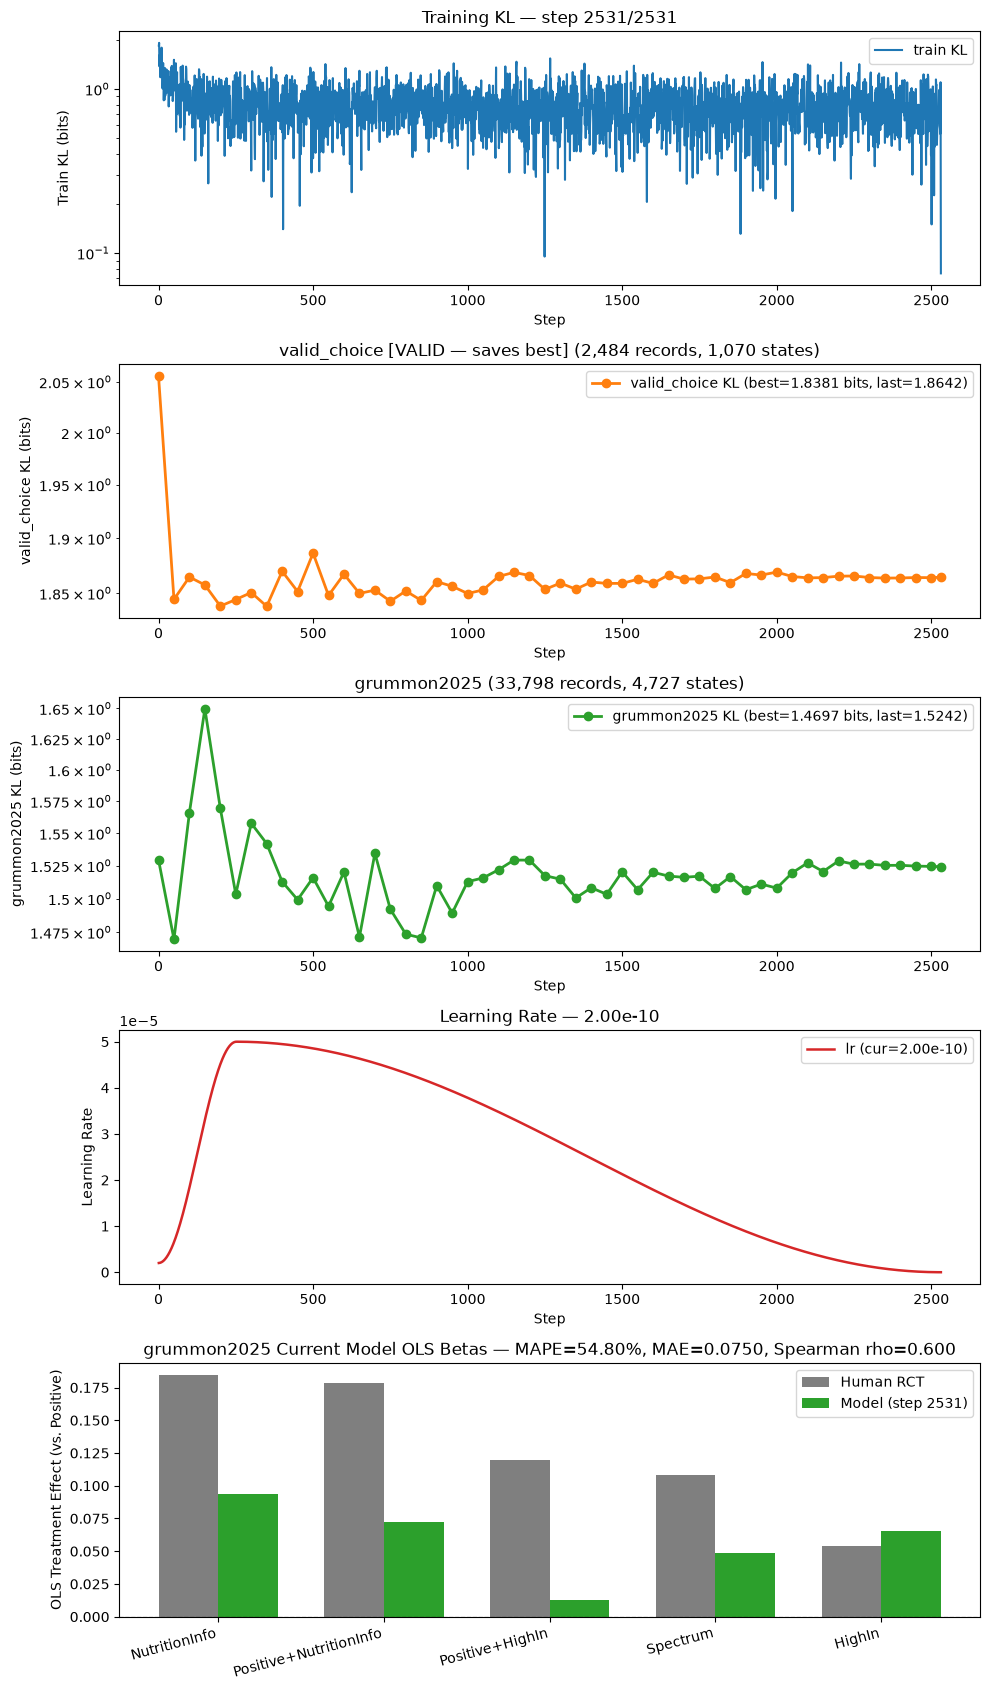

,epoch,step,train_kl,valid_choice_kl,grummon2025_kl,grummon2025_OLS MAPE (%),grummon2025_OLS MAE,grummon2025_OLS MSE,grummon2025_Spearman rho
0,0,0,—,2.0559,1.5294,63.87,0.0650,0.0054,0.5000
1,1,50,1.5049,1.8443,1.4697,71.83,0.1025,0.0134,-0.5000
2,1,100,1.0564,1.8644,1.5660,62.95,0.0886,0.0103,-0.6000
3,1,150,0.6590,1.8573,1.6496,54.08,0.0690,0.0064,0.2000
4,1,200,0.8697,1.8383,1.5693,44.85,0.0618,0.0055,0.5000
5,1,250,0.6452,1.8442,1.5032,54.60,0.0744,0.0073,-0.1000
6,1,300,0.3183,1.8504,1.5577,60.08,0.0868,0.0097,0.3000
7,1,350,0.8450,1.8381,1.5419,58.86,0.0857,0.0097,-0.3000
8,1,400,0.5440,1.8696,1.5128,62.52,0.0820,0.0079,-0.1000
9,1,450,0.8236,1.8514,1.4991,67.94,0.0943,0.0111,0.5000


,human,model,abs_diff
NutritionInfo,0.1844,0.0939,0.0905
Positive+NutritionInfo,0.1788,0.0720,0.1068
Positive+HighIn,0.1194,0.0127,0.1067
Spectrum,0.1083,0.0487,0.0596
HighIn,0.0541,0.0653,0.0112


In [76]:
plotter = trainer.train()